Cargando el archivo de Excel...
Registros cargados: 1986848
  codigoestacion codigosensor    fechaobservacion  valorobservado  \
0     0027015290         0103 2019-02-17 14:20:00             4.5   
1     0027015300         0103 2007-07-31 06:20:00             1.3   
2     0027015290         0103 2017-05-28 04:50:00             1.3   
3     0027015290         0103 2012-03-01 14:00:00             5.6   
4     0027015290         0103 2008-01-19 04:20:00             1.0   

   nombreestacion departamento municipio zonahidrografica   latitud  \
0  PAJARITO - AUT    ANTIOQUIA  MEDELLÍN            NECHÍ  6.286333   
1      VILLANUEVA    ANTIOQUIA  MEDELLÍN            NECHÍ  6.253000   
2  PAJARITO - AUT    ANTIOQUIA  MEDELLÍN            NECHÍ  6.286333   
3  PAJARITO - AUT    ANTIOQUIA  MEDELLÍN            NECHÍ  6.286333   
4  PAJARITO - AUT    ANTIOQUIA  MEDELLÍN            NECHÍ  6.286333   

    longitud          descripcionsensor unidadmedida  
0 -75.612792  Velocidad Viento (10 min)    

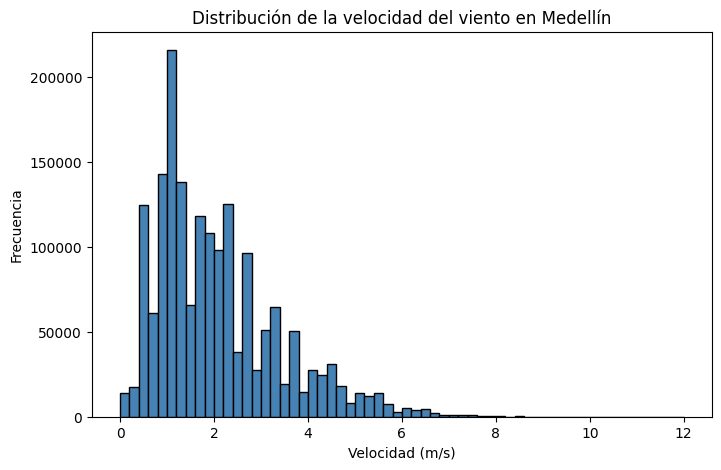

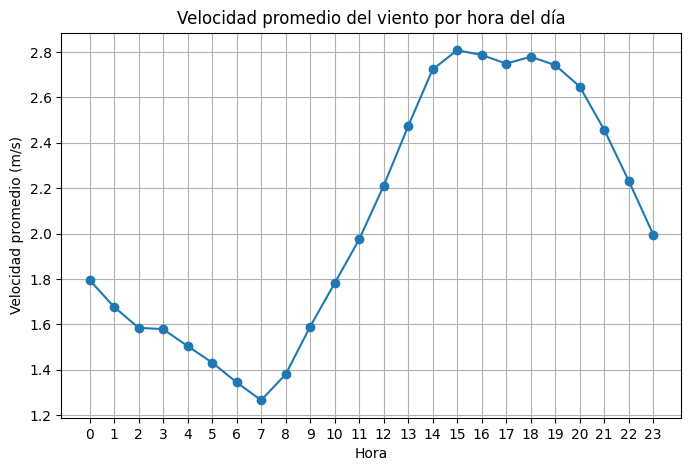

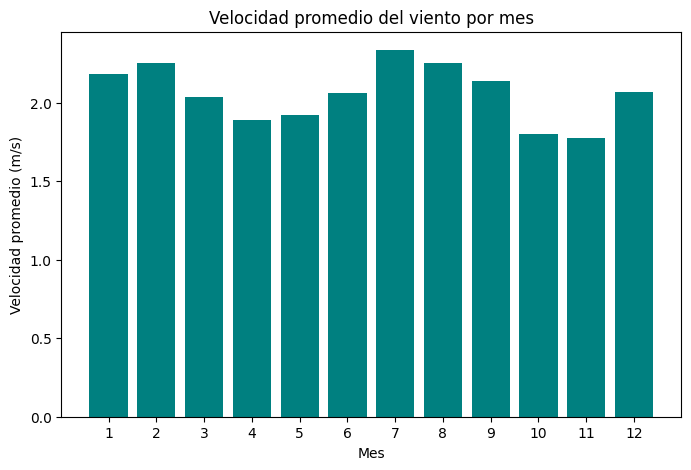

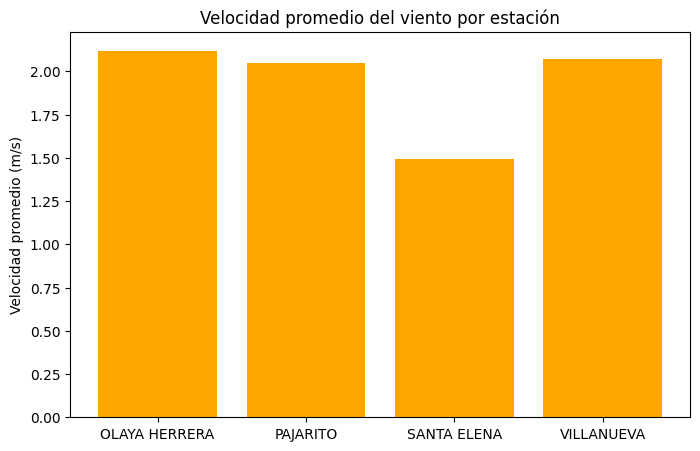

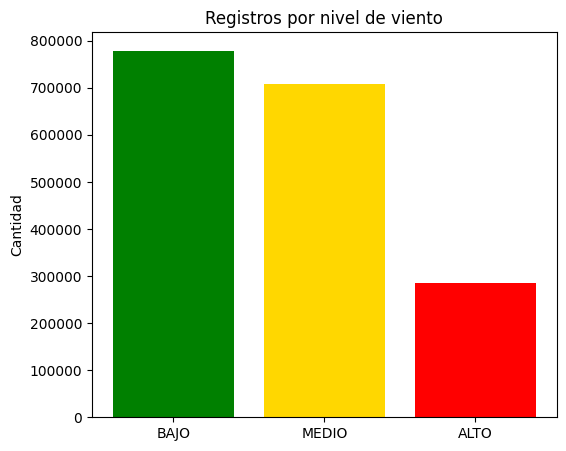


========== MODELO NAIVE BAYES ==========
Datos de entrenamiento: 1239443
Datos de prueba: 531190

========== RESULTADOS ==========
Exactitud (accuracy) del modelo: 51.58 %

Reporte de clasificación:
              precision    recall  f1-score   support

        ALTO       0.43      0.18      0.25     85346
        BAJO       0.60      0.65      0.62    233718
       MEDIO       0.45      0.51      0.48    212126

    accuracy                           0.52    531190
   macro avg       0.49      0.44      0.45    531190
weighted avg       0.51      0.52      0.50    531190

Exactitud si siempre se predice 'BAJO': 44.0 %

Matriz de confusión:
[[151045  75561   7112]
 [ 91183 107943  13000]
 [ 11518  58826  15002]]


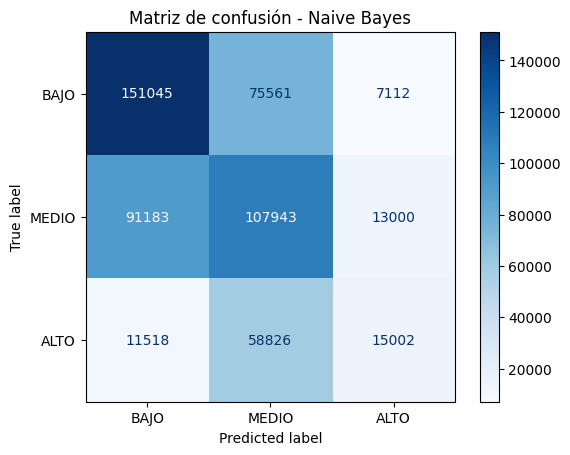


========== COMPARACIÓN ==========
Sin día de la semana: 51.58 %
Con día de la semana: 51.6 %

========== PREDICCIONES DE EJEMPLO ==========
Hora 15 -> nivel de viento predicho: ALTO
   Probabilidad ALTO : 42.72 %
   Probabilidad BAJO : 17.73 %
   Probabilidad MEDIO : 39.55 %
Hora 7 -> nivel de viento predicho: BAJO
   Probabilidad ALTO : 2.47 %
   Probabilidad BAJO : 66.97 %
   Probabilidad MEDIO : 30.55 %

Modelo exportado en modelo_naive_bayes.json
JSONINI{"clases": ["ALTO", "BAJO", "MEDIO"], "estaciones": ["OLAYA HERRERA", "PAJARITO", "VILLANUEVA", "SANTA ELENA"], "prob_clase": [0.16067, 0.439988, 0.399342], "prob_hora": [[0.022785, 0.016936, 0.012628, 0.01323, 0.009716, 0.006954, 0.005086, 0.004072, 0.005799, 0.010057, 0.01555, 0.026978, 0.043236, 0.065433, 0.082022, 0.086767, 0.084849, 0.082906, 0.086265, 0.085482, 0.081807, 0.067276, 0.050441, 0.033726], [0.045922, 0.050762, 0.053929, 0.055112, 0.057921, 0.060585, 0.065123, 0.06979, 0.064196, 0.052723, 0.043241, 0.037265, 0.0318

In [10]:
# ==============================================================
# PROYECTO FINAL - MINERÍA DE DATOS
# Clasificación de la velocidad del viento en Medellín con Naive Bayes
#
# Fuente de datos: Portal de Datos Abiertos de Colombia (datos.gov.co)
# Conjunto "Velocidad del Viento", filtrado por el municipio de Medellín
# https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Velocidad-del-Viento/sgfv-3yp8
# ==============================================================

# Librería para leer más rápido el Excel (el archivo pesa 100 MB)
!pip install -q python-calamine

import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


# --------------------------------------------------------------
# 1. CARGA DE LOS DATOS
# --------------------------------------------------------------
# El archivo de Excel tiene dos hojas (Medellin_1 y Medellin_2) porque
# Excel no permite más de 1.048.576 filas por hoja.
# Los códigos se leen como texto para no perder los ceros de la izquierda.

print("Cargando el archivo de Excel...")
ruta = "viento_medellin.xlsx"

hoja1 = pd.read_excel(ruta, sheet_name="Medellin_1", engine="calamine", dtype={"codigoestacion": str, "codigosensor": str})
hoja2 = pd.read_excel(ruta, sheet_name="Medellin_2", engine="calamine", dtype={"codigoestacion": str, "codigosensor": str})

# Unimos las dos hojas en un solo DataFrame
datos = pd.concat([hoja1, hoja2], ignore_index=True)

print("Registros cargados:", len(datos))
print(datos.head())


# --------------------------------------------------------------
# 2. EXPLORACIÓN INICIAL (ver qué tan sucios están los datos)
# --------------------------------------------------------------
print("\n========== EXPLORACIÓN INICIAL ==========")
print("Filas y columnas:", datos.shape)
print("\nTipos de datos:")
print(datos.dtypes)

print("\nValores nulos por columna:")
print(datos.isnull().sum())

print("\nFilas duplicadas exactas:", datos.duplicated().sum())

# Revisamos los valores distintos de las columnas de texto
print("\nNombres de estación por código:")
print(datos.groupby(["codigoestacion", "nombreestacion"]).size())

print("\nDepartamento:")
print(datos["departamento"].value_counts())

print("\nMunicipio:")
print(datos["municipio"].value_counts())

print("\nDescripción del sensor:")
print(datos["descripcionsensor"].value_counts())

print("\nSensores por estación:")
print(datos.groupby(["codigoestacion", "codigosensor"]).size())

print("\nEstadísticas de la velocidad del viento (m/s):")
print(datos["valorobservado"].describe())


# --------------------------------------------------------------
# 3. LIMPIEZA DE LOS DATOS
# --------------------------------------------------------------
print("\n========== LIMPIEZA ==========")
filas_iniciales = len(datos)

# 3.1 Estandarizar textos: quitar espacios y pasar todo a mayúsculas
# (hay valores como "ANTIOQUIA" y "Antioquia", "MEDELLÍN" y "Medellín")
columnas_texto = ["nombreestacion", "departamento", "municipio", "zonahidrografica", "descripcionsensor"]
for col in columnas_texto:
    datos[col] = datos[col].astype(str).str.strip().str.upper()

# 3.2 Unificar el nombre de las estaciones usando su código
# (una misma estación aparece con varios nombres, por ejemplo
#  "AEROPUERTO OLAYA HERRERA", "APTO OLAYA HERRERA - TX GPRS" y
#  "AEROPUERTO OLAYA HERRERA [27015330]")
nombres_estaciones = {
    "0027015330": "OLAYA HERRERA",
    "0027015290": "PAJARITO",
    "0027015300": "VILLANUEVA",
    "0027010810": "SANTA ELENA"
}
datos["nombreestacion"] = datos["codigoestacion"].map(nombres_estaciones)

# 3.3 Convertir los tipos de datos
datos["fechaobservacion"] = pd.to_datetime(datos["fechaobservacion"], errors="coerce")
datos["valorobservado"] = pd.to_numeric(datos["valorobservado"], errors="coerce")

# 3.4 Eliminar filas con nulos en las columnas importantes
datos = datos.dropna(subset=["fechaobservacion", "valorobservado", "nombreestacion"])
filas_sin_nulos = len(datos)
print("Filas después de quitar nulos:", filas_sin_nulos)

# 3.5 Eliminar duplicados exactos
datos = datos.drop_duplicates()
filas_sin_duplicados = len(datos)
print("Filas después de quitar duplicados exactos:", filas_sin_duplicados)

# 3.6 Eliminar mediciones repetidas de la misma estación en la misma fecha y hora
# (la estación Olaya Herrera tiene dos sensores, el 0103 y el 0111, que
#  a veces miden al mismo tiempo; dejamos una sola medición por momento)
datos = datos.sort_values(["codigoestacion", "fechaobservacion", "codigosensor"])
datos = datos.drop_duplicates(subset=["codigoestacion", "fechaobservacion"], keep="first")
filas_sin_repetidas = len(datos)
print("Filas después de quitar mediciones repetidas por estación y fecha:", filas_sin_repetidas)

# 3.7 Eliminar valores atípicos (outliers)
# La velocidad no puede ser negativa, y valores mayores a 30 m/s (108 km/h)
# serían vientos de huracán, que no ocurren en Medellín: son errores del sensor.
# No usamos la regla del rango intercuartílico porque su límite queda en 5.1 m/s
# y borraría miles de mediciones reales de viento fuerte, que son las que
# queremos aprender a clasificar.
print("Valores negativos:", (datos["valorobservado"] < 0).sum())
print("Valores mayores a 30 m/s:", (datos["valorobservado"] > 30).sum())
datos = datos[(datos["valorobservado"] >= 0) & (datos["valorobservado"] <= 30)]
filas_sin_atipicos = len(datos)
print("Filas después de quitar atípicos:", filas_sin_atipicos)

# 3.8 Eliminar columnas que no aportan al modelo
# (tienen un solo valor o repiten información de otra columna)
datos = datos.drop(columns=["codigosensor", "departamento", "municipio", "zonahidrografica",
                            "latitud", "longitud", "descripcionsensor", "unidadmedida"])

print("\nResumen de la limpieza:")
print("Filas iniciales:", filas_iniciales)
print("Filas finales:  ", len(datos))
print("Filas eliminadas:", filas_iniciales - len(datos))

# Guardamos los datos limpios por si se necesitan después
datos.to_csv("viento_medellin_limpio.csv", index=False)


# --------------------------------------------------------------
# 4. PREPARACIÓN DE VARIABLES PARA NAIVE BAYES
# --------------------------------------------------------------
print("\n========== PREPARACIÓN DE VARIABLES ==========")

# Sacamos variables de la fecha
datos["hora"] = datos["fechaobservacion"].dt.hour
datos["mes"] = datos["fechaobservacion"].dt.month
datos["dia_semana"] = datos["fechaobservacion"].dt.dayofweek   # 0 = lunes, 6 = domingo

# El modelo espera categorías numeradas desde 0, por eso al mes se le resta 1
datos["mes_codigo"] = datos["mes"] - 1

# La estación se pasa a número porque el modelo solo recibe números
codigo_estacion = {"OLAYA HERRERA": 0, "PAJARITO": 1, "VILLANUEVA": 2, "SANTA ELENA": 3}
datos["estacion"] = datos["nombreestacion"].map(codigo_estacion)


# Variable objetivo: nivel del viento según la escala de Beaufort
#   BAJO  -> 0 a 1.5 m/s   (calma y ventolina)
#   MEDIO -> 1.6 a 3.3 m/s (brisa muy débil)
#   ALTO  -> más de 3.3 m/s (brisa débil o más fuerte)
def clasificar_viento(velocidad):
    if velocidad <= 1.5:
        return "BAJO"
    elif velocidad <= 3.3:
        return "MEDIO"
    else:
        return "ALTO"


datos["nivel_viento"] = datos["valorobservado"].apply(clasificar_viento)

print("Cantidad de registros por nivel de viento:")
print(datos["nivel_viento"].value_counts())


# --------------------------------------------------------------
# 5. GRÁFICAS DE ANÁLISIS
# --------------------------------------------------------------

# Histograma de la velocidad del viento
plt.figure(figsize=(8, 5))
plt.hist(datos["valorobservado"], bins=60, range=(0, 12), color="steelblue", edgecolor="black")
plt.title("Distribución de la velocidad del viento en Medellín")
plt.xlabel("Velocidad (m/s)")
plt.ylabel("Frecuencia")
plt.show()

# Velocidad promedio por hora del día
promedio_hora = datos.groupby("hora")["valorobservado"].mean()
plt.figure(figsize=(8, 5))
plt.plot(promedio_hora.index, promedio_hora.values, marker="o")
plt.title("Velocidad promedio del viento por hora del día")
plt.xlabel("Hora")
plt.ylabel("Velocidad promedio (m/s)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

# Velocidad promedio por mes
promedio_mes = datos.groupby("mes")["valorobservado"].mean()
plt.figure(figsize=(8, 5))
plt.bar(promedio_mes.index, promedio_mes.values, color="teal")
plt.title("Velocidad promedio del viento por mes")
plt.xlabel("Mes")
plt.ylabel("Velocidad promedio (m/s)")
plt.xticks(range(1, 13))
plt.show()

# Velocidad promedio por estación
promedio_estacion = datos.groupby("nombreestacion")["valorobservado"].mean()
plt.figure(figsize=(8, 5))
plt.bar(promedio_estacion.index, promedio_estacion.values, color="orange")
plt.title("Velocidad promedio del viento por estación")
plt.ylabel("Velocidad promedio (m/s)")
plt.show()

# Cantidad de registros por nivel de viento
etiquetas = ["BAJO", "MEDIO", "ALTO"]
conteo = datos["nivel_viento"].value_counts().reindex(etiquetas)
plt.figure(figsize=(6, 5))
plt.bar(conteo.index, conteo.values, color=["green", "gold", "red"])
plt.title("Registros por nivel de viento")
plt.ylabel("Cantidad")
plt.show()


# --------------------------------------------------------------
# 6. ENTRENAMIENTO DEL MODELO NAIVE BAYES
# --------------------------------------------------------------
print("\n========== MODELO NAIVE BAYES ==========")

# El conjunto de datos solo trae la fecha, la estación y la velocidad,
# así que las variables para predecir son la hora, el mes y la estación.
X = datos[["hora", "mes_codigo", "estacion"]]
y = datos["nivel_viento"]

# 70% para entrenar y 30% para probar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

# Usamos CategoricalNB porque todas las variables son categorías.
# min_categories le dice cuántas categorías tiene cada variable:
# 24 horas, 12 meses y 4 estaciones.
modelo = CategoricalNB(min_categories=[24, 12, 4])
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)


# --------------------------------------------------------------
# 7. EVALUACIÓN DEL MODELO
# --------------------------------------------------------------
print("\n========== RESULTADOS ==========")
exactitud = accuracy_score(y_test, y_pred)
print("Exactitud (accuracy) del modelo:", round(exactitud * 100, 2), "%")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

# Comparamos con un modelo "tonto" que siempre dice la clase más común
clase_comun = y_train.value_counts().idxmax()
exactitud_base = (y_test == clase_comun).mean()
print("Exactitud si siempre se predice '" + clase_comun + "':", round(exactitud_base * 100, 2), "%")

# Matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=etiquetas)
print("\nMatriz de confusión:")
print(matriz)

disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=etiquetas)
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - Naive Bayes")
plt.show()


# --------------------------------------------------------------
# 8. ¿SIRVE EL DÍA DE LA SEMANA?
# --------------------------------------------------------------
# Probamos agregar el día de la semana para ver si mejora el modelo.
# El viento no debería depender de si es lunes o sábado.
X2 = datos[["hora", "mes_codigo", "estacion", "dia_semana"]]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.3, random_state=42, stratify=y)
modelo2 = CategoricalNB(min_categories=[24, 12, 4, 7])
modelo2.fit(X2_train, y2_train)
exactitud2 = accuracy_score(y2_test, modelo2.predict(X2_test))

print("\n========== COMPARACIÓN ==========")
print("Sin día de la semana:", round(exactitud * 100, 2), "%")
print("Con día de la semana:", round(exactitud2 * 100, 2), "%")


# --------------------------------------------------------------
# 9. PRUEBA CON UN DATO NUEVO
# --------------------------------------------------------------
# Ejemplo: ¿cómo estará el viento a las 3 p.m. de agosto
# en la estación Olaya Herrera? ¿Y a las 7 a.m.?
print("\n========== PREDICCIONES DE EJEMPLO ==========")
nuevos = pd.DataFrame({
    "hora": [15, 7],
    "mes_codigo": [8 - 1, 8 - 1],
    "estacion": [codigo_estacion["OLAYA HERRERA"], codigo_estacion["OLAYA HERRERA"]]
})

predicciones = modelo.predict(nuevos)
probabilidades = modelo.predict_proba(nuevos)

for i in range(len(nuevos)):
    print("Hora", nuevos["hora"][i], "-> nivel de viento predicho:", predicciones[i])
    for j in range(len(modelo.classes_)):
        print("   Probabilidad", modelo.classes_[j], ":", round(probabilidades[i][j] * 100, 2), "%")


# --------------------------------------------------------------
# 10. EXPORTAR EL MODELO PARA LA PÁGINA WEB
# --------------------------------------------------------------
# Naive Bayes es solo un conjunto de tablas de probabilidades.
# Las guardamos en un archivo JSON para que la página pueda calcular
# la predicción directamente en el navegador.
import numpy as np

reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
histograma, bordes = np.histogram(datos["valorobservado"], bins=24, range=(0, 12))
nivel_por_hora = pd.crosstab(datos["hora"], datos["nivel_viento"], normalize="index")[etiquetas]
hora_estacion = datos.groupby(["nombreestacion", "hora"])["valorobservado"].mean().unstack(0)

exportar = {
    "clases": list(modelo.classes_),
    "estaciones": list(codigo_estacion.keys()),
    "prob_clase": np.exp(modelo.class_log_prior_).round(6).tolist(),
    "prob_hora": np.exp(modelo.feature_log_prob_[0]).round(6).tolist(),
    "prob_mes": np.exp(modelo.feature_log_prob_[1]).round(6).tolist(),
    "prob_estacion": np.exp(modelo.feature_log_prob_[2]).round(6).tolist(),
    "limpieza": {
        "iniciales": int(filas_iniciales),
        "sin_nulos": int(filas_sin_nulos),
        "sin_duplicados": int(filas_sin_duplicados),
        "sin_repetidas": int(filas_sin_repetidas),
        "sin_atipicos": int(filas_sin_atipicos)
    },
    "exactitud": round(float(exactitud), 4),
    "exactitud_base": round(float(exactitud_base), 4),
    "exactitud_con_dia": round(float(exactitud2), 4),
    "clase_comun": clase_comun,
    "entrenamiento": int(len(X_train)),
    "prueba": int(len(X_test)),
    "matriz": matriz.tolist(),
    "reporte": {c: {k: round(float(v), 4) for k, v in reporte[c].items()} for c in etiquetas},
    "conteo_niveles": [int(conteo[c]) for c in etiquetas],
    "promedio_hora": promedio_hora.round(3).tolist(),
    "promedio_mes": promedio_mes.round(3).tolist(),
    "promedio_estacion": {k: round(float(v), 3) for k, v in promedio_estacion.items()},
    "registros_estacion": {k: int(v) for k, v in datos["nombreestacion"].value_counts().items()},
    "hora_estacion": {c: hora_estacion[c].round(3).tolist() for c in hora_estacion.columns},
    "nivel_por_hora": {c: nivel_por_hora[c].round(4).tolist() for c in etiquetas},
    "histograma": histograma.tolist(),
    "fecha_min": str(datos["fechaobservacion"].min()),
    "fecha_max": str(datos["fechaobservacion"].max()),
    "velocidad_media": round(float(datos["valorobservado"].mean()), 3),
    "velocidad_max": round(float(datos["valorobservado"].max()), 2)
}

with open("modelo_naive_bayes.json", "w", encoding="utf-8") as archivo:
    json.dump(exportar, archivo, ensure_ascii=False)

print("\nModelo exportado en modelo_naive_bayes.json")
print("JSONINI" + json.dumps(exportar, ensure_ascii=False) + "JSONFIN")


In [11]:
print(open("modelo_naive_bayes.json", encoding="utf-8").read())

{"clases": ["ALTO", "BAJO", "MEDIO"], "estaciones": ["OLAYA HERRERA", "PAJARITO", "VILLANUEVA", "SANTA ELENA"], "prob_clase": [0.16067, 0.439988, 0.399342], "prob_hora": [[0.022785, 0.016936, 0.012628, 0.01323, 0.009716, 0.006954, 0.005086, 0.004072, 0.005799, 0.010057, 0.01555, 0.026978, 0.043236, 0.065433, 0.082022, 0.086767, 0.084849, 0.082906, 0.086265, 0.085482, 0.081807, 0.067276, 0.050441, 0.033726], [0.045922, 0.050762, 0.053929, 0.055112, 0.057921, 0.060585, 0.065123, 0.06979, 0.064196, 0.052723, 0.043241, 0.037265, 0.031803, 0.027673, 0.023595, 0.022794, 0.023663, 0.024695, 0.02537, 0.027092, 0.029019, 0.031793, 0.03554, 0.040393], [0.042813, 0.042442, 0.040878, 0.039741, 0.038736, 0.036399, 0.031938, 0.027172, 0.032765, 0.042997, 0.051349, 0.053848, 0.052971, 0.048411, 0.044333, 0.043387, 0.042852, 0.041442, 0.040456, 0.038757, 0.038159, 0.040454, 0.043292, 0.044409]], "prob_mes": [[0.10498, 0.086446, 0.08388, 0.06484, 0.070564, 0.086441, 0.110965, 0.099185, 0.095464, 0.0605